# Лабораторная работа №2
## Исследование логистической и линейной регрессии

**Задача:** повторить пункты 2–4 первой лабораторной для логистической регрессии (классификация) и линейной регрессии (прогноз продаж): sklearn-бейзлайны, проверка улучшений на CV, собственные реализации, обучение и сравнение.

Используем условия из [первой работы](research-1.ipynb):
- [Steam Game Hits](https://www.kaggle.com/datasets/vedauv/what-makes-a-steam-game-a-hit-8000-games): цель `hit`, основная метрика **Average Precision (AP)**; дополнительно ROC AUC, F1, precision, recall, balanced accuracy и accuracy. `hit=1` — верхние 20% по выручке. Данные **синтетические** (см. `data/steam/README.md`), выводы относятся к генератору. Классифицируем по порогу вероятности >0.5, при равенстве выбираем 0.
- [Video Games Sales](https://www.kaggle.com/datasets/ulrikthygepedersen/video-games-sales): цель `global_sales`, основная метрика **MAE**, дополнительно RMSE и R². Продажи измеряются в миллионах копий. Накопленные продажи не имеют единого горизонта наблюдения; это исторический эксперимент, а не проверенный прогноз будущих релизов.

AP оценивает ранжирование редкого класса без выбора одного порога; MAE даёт интерпретируемую абсолютную ошибку, RMSE выделяет крупные промахи. Выручка, аудитория и отзывы Steam, ранг продаж и региональные продажи исключены как недоступные до релиза или раскрывающие ответ. Число wishlist — дорелизное по описанию автора; остальные используемые характеристики предполагаем известными перед релизом.

Разбиения в точности повторяют первую работу (seed=42): 80/20, стратификация для Steam, группировка по названию для продаж; 3-fold CV только внутри train. Ноутбук самодостаточен, выполняется сверху вниз из корня проекта. Зависимости — существующий `requirements.txt`. Результаты доступны в ячейках; отдельно сохраняются только две таблицы в `results/research-2/`.

### Импорт и воспроизводимость
Загружаем существующие зависимости, ограничиваем потоки двумя и фиксируем seed. Параллельные дочерние процессы для CV не запускаем. Никакие ячейки первой работы не требуется выполнять заранее.

In [1]:
import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
os.environ.setdefault("OMP_NUM_THREADS", "2")
from pathlib import Path
import time
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown
from sklearn.base import BaseEstimator, ClassifierMixin, RegressorMixin, TransformerMixin, clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, GroupShuffleSplit, StratifiedKFold, GroupKFold, GridSearchCV, cross_val_score
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (average_precision_score, roc_auc_score, accuracy_score,
    balanced_accuracy_score, precision_score, recall_score, f1_score,
    mean_absolute_error, mean_squared_error, r2_score, PrecisionRecallDisplay, ConfusionMatrixDisplay)
from sklearn.utils.validation import check_X_y, check_array, check_is_fitted
from threadpoolctl import threadpool_limits
SEED = 42
np.random.seed(SEED)
thread_limit = threadpool_limits(limits=2)
sns.set_theme(style="whitegrid")
ROOT = Path.cwd()
assert (ROOT / "data").exists(), "Откройте ноутбук из корня проекта"
RESULTS = ROOT / "results/research-2"
RESULTS.mkdir(parents=True, exist_ok=True)
print({"Python": platform.python_version(), "numpy": np.__version__,
       "pandas": pd.__version__, "sklearn": sklearn.__version__})

{'Python': '3.14.8', 'numpy': '2.5.5', 'pandas': '3.1.1', 'sklearn': '1.9.1'}


### Подготовка данных и разбиений из первой лабораторной
Читаем те же CSV, удаляем полные дубликаты и строки без корректной цели/названия, используем тот же белый список признаков. Пропуски признаков обрабатываются позже внутри Pipeline. Проверяем отсутствие пересечений групп в тесте и CV; никакие сохранённые результаты первой работы не нужны.

In [2]:
steam = pd.read_csv(ROOT / "data/steam/steam_game_hits.csv")
sales = pd.read_csv(ROOT / "data/sales/video_games_sales.csv")
steam = steam.drop_duplicates().dropna(subset=["hit"]).reset_index(drop=True)
sales = sales.drop_duplicates().dropna(subset=["global_sales", "name"]).copy()
sales = sales.loc[np.isfinite(sales.global_sales) & (sales.global_sales >= 0)].reset_index(drop=True)
steam_num = ["release_year", "is_indie", "team_size", "price_usd", "has_multiplayer",
             "early_access", "controller_support", "languages_supported", "file_size_gb",
             "wishlists_k", "trailer_views_k"]
steam_cat = ["genre"]
sales_num, sales_cat = ["year"], ["platform", "genre", "publisher"]
Xc, yc = steam[steam_num + steam_cat].copy(), steam.hit.astype(int)
Xr, yr = sales[sales_num + sales_cat].copy(), sales.global_sales.astype(float)
groups = sales.name.str.normalize("NFKC").str.strip().str.casefold()
ic_train, ic_test = train_test_split(np.arange(len(Xc)), test_size=0.2,
                                     stratify=yc, random_state=SEED)
ir_train, ir_test = next(GroupShuffleSplit(n_splits=1, test_size=0.2,
                            random_state=SEED).split(Xr, yr, groups))
Xc_train, Xc_test, yc_train, yc_test = Xc.iloc[ic_train], Xc.iloc[ic_test], yc.iloc[ic_train], yc.iloc[ic_test]
Xr_train, Xr_test, yr_train, yr_test = Xr.iloc[ir_train], Xr.iloc[ir_test], yr.iloc[ir_train], yr.iloc[ir_test]
g_train, g_test = groups.iloc[ir_train], groups.iloc[ir_test]
assert not set(g_train) & set(g_test)
cv_c = list(StratifiedKFold(3, shuffle=True, random_state=SEED).split(Xc_train, yc_train))
cv_r = list(GroupKFold(3).split(Xr_train, yr_train, g_train))
for a, b in cv_r:
    assert not set(g_train.iloc[a]) & set(g_train.iloc[b])
display(pd.DataFrame({"Задача": ["Классификация", "Регрессия"],
    "train": [len(ic_train), len(ir_train)], "test": [len(ic_test), len(ir_test)]}))
print("Доля hit в train/test:", round(yc_train.mean(), 3), round(yc_test.mean(), 3))

,Задача,train,test
0,Классификация,6400,1600
1,Регрессия,13272,3326


Доля hit в train/test: 0.2 0.2


## 2. Создание бейзлайна и оценка качества
### 2a. Модели sklearn
Логистическая регрессия моделирует вероятность `hit=1` как σ(wᵀx+b); бейзлайн — L2-регуляризация с C=1, без весов классов. Линейная регрессия минимизирует сумму квадратов ошибок продаж, без регуляризации. Она оптимизирует MSE, хотя выбирать улучшения будем по MAE — это разные критерии.

Числовые признаки заполняем медианой и стандартизуем; категориальные — наиболее частым значением и one-hot. Полное one-hot создаёт линейную зависимость со свободным членом, поэтому решение OLS находим устойчивым методом наименьших квадратов; коэффициенты могут быть неединственными, но прогнозы на том же пространстве определены. Неизвестные категории кодируются нулями. Все статистики вычисляются только на train соответствующего fold.

In [3]:
def prep(task, engineered=False):
    num = list(steam_num if task == "c" else sales_num)
    cat = list(steam_cat if task == "c" else sales_cat)
    if engineered:
        if task == "c": num += ["is_free", "wishlist_trailer_ratio"]
        else:
            num += ["year_squared"]
            cat += ["platform_genre"]
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False,
                                   min_frequency=0.01 if engineered else None))]), cat)
    ], sparse_threshold=0)

def logistic(C=1., class_weight=None):
    return LogisticRegression(C=C, class_weight=class_weight, solver="lbfgs", max_iter=3000, tol=1e-9)

def pipeline(task, model, engineered=False):
    steps = [("features", Features(task))] if engineered else []
    return Pipeline(steps + [("prep", prep(task, engineered)), ("model", model)])

base_c = pipeline("c", logistic())
base_r = pipeline("r", LinearRegression())
base_c.fit(Xc_train, yc_train)
base_r.fit(Xr_train, yr_train)
print("Бейзлайны обучены.")

Бейзлайны обучены.


### 2b. Оценка на отложенном тесте
Dummy показывает минимальный ориентир: частота классов для классификации и медиана продаж для MAE. Не обрезаем отрицательные прогнозы регрессии: это свойство линейной модели, их число выводим отдельно. Одно и то же правило применяется к sklearn и собственной модели, включая CV.

In [4]:
rows, predictions = [], {}
def evaluate(name, task, model):
    X, y = (Xc_test, yc_test) if task == "c" else (Xr_test, yr_test)
    start = time.perf_counter()
    if task == "c":
        prob = model.predict_proba(X)[:, 1]
        pred = (prob > 0.5).astype(int)
        metrics = {"AP": average_precision_score(y, prob), "ROC_AUC": roc_auc_score(y, prob),
            "F1": f1_score(y, pred, zero_division=0), "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred, zero_division=0), "Balanced_accuracy": balanced_accuracy_score(y, pred),
            "Accuracy": accuracy_score(y, pred)}
        predictions[(task, name)] = (pred, prob)
    else:
        pred = model.predict(X)
        metrics = {"MAE": mean_absolute_error(y, pred), "RMSE": np.sqrt(mean_squared_error(y, pred)),
                   "R2": r2_score(y, pred), "negative_predictions": int((pred < 0).sum())}
        predictions[(task, name)] = pred
    rows.append({"task": task, "model": name, **metrics, "predict_seconds": time.perf_counter() - start})
    return pd.DataFrame([rows[-1]])


dummy_c = DummyClassifier(strategy="prior").fit(Xc_train, yc_train)
dummy_r = DummyRegressor(strategy="median").fit(Xr_train, yr_train)
for name, task, model in [("Dummy", "c", dummy_c), ("Dummy", "r", dummy_r),
                          ("sklearn baseline", "c", base_c), ("sklearn baseline", "r", base_r)]:
    display(evaluate(name, task, model))

,task,model,AP,ROC_AUC,F1,Precision,Recall,Balanced_accuracy,Accuracy,predict_seconds
0,c,Dummy,0.2,0.5,0.0,0.0,0.0,0.5,0.8,0.033418


,task,model,MAE,RMSE,R2,negative_predictions,predict_seconds
0,r,Dummy,0.456185,1.616683,-0.051272,0,0.003448


,task,model,AP,ROC_AUC,F1,Precision,Recall,Balanced_accuracy,Accuracy,predict_seconds
0,c,sklearn baseline,0.69286,0.877195,0.568627,0.763158,0.453125,0.708984,0.8625,0.039863


,task,model,MAE,RMSE,R2,negative_predictions,predict_seconds
0,r,sklearn baseline,0.534781,1.471357,0.129234,408,0.036712


## 3. Улучшение бейзлайна
### 3a. Гипотезы
- **H1: признаки и распределения.** В Steam логарифмируем размер команды, цену, размер файла, wishlist и просмотры; добавляем бесплатность и логарифм отношения wishlist/просмотров. Это позволяет логистической модели выразить нелинейность по исходным величинам. Для продаж добавляем квадрат центрированного года и взаимодействие платформа–жанр. Категории с частотой <1% объединяем внутри каждого train-fold.
- **H2: регуляризация и дисбаланс.** Для классификации проверяем C ∈ {0.01, 0.1, 1, 10} и веса классов {None, balanced}; balanced не гарантирует улучшения AP. Для продаж проверяем Ridge с α ∈ {0.1, 1, 10, 100}. L2 снижает нестабильность коэффициентов при связанных и редких признаках; Ridge остаётся линейной регрессией с регуляризацией.
- **H3: логарифм цели продаж.** Проверяем линейную регрессию и Ridge для log1p продаж с обратным expm1. При обучении оптимизируется ошибка в логарифмической шкале; CV и тест оцениваются в исходных миллионах копий. Обратное преобразование не является несмещённой оценкой среднего, а отрицательные прогнозы возможны и здесь.

### 3b. Реализация преобразований
Преобразователь не использует цель или статистики теста. Центр года фиксирован заранее (2000), чтобы квадрат не создавал огромных значений. Успешность гипотез определяем по CV, а не по ожиданиям или тестовым метрикам.

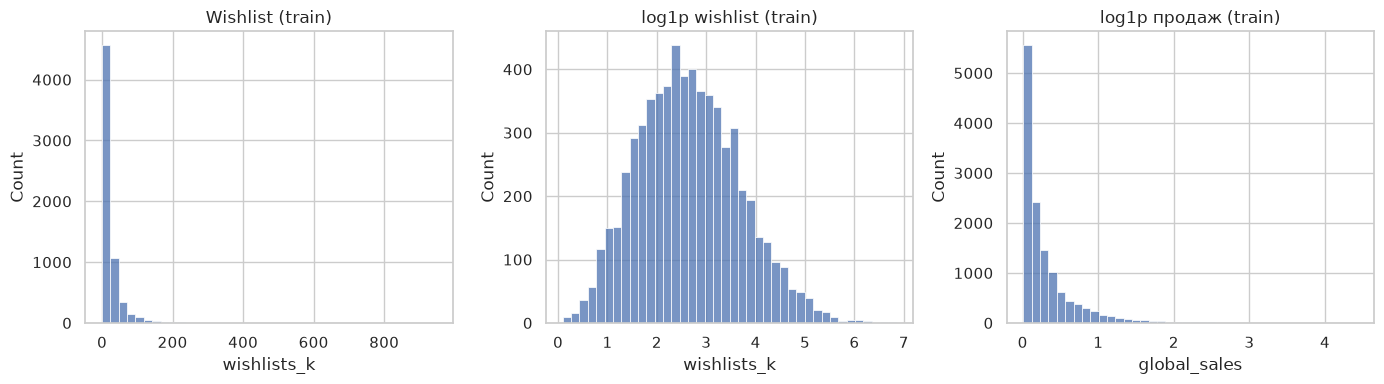

In [5]:
class Features(TransformerMixin, BaseEstimator):
    def __init__(self, task="c"):
        self.task = task
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        out = X.copy()
        if self.task == "c":
            out["is_free"] = (out.price_usd == 0).astype(float)
            out["wishlist_trailer_ratio"] = np.log1p(out.wishlists_k) - np.log1p(out.trailer_views_k)
            for col in ["team_size", "price_usd", "file_size_gb", "wishlists_k", "trailer_views_k"]:
                out[col] = np.log1p(out[col])
        else:
            out["year_squared"] = (out.year - 2000) ** 2
            out["platform_genre"] = out.platform.fillna("unknown") + " / " + out.genre.fillna("unknown")
        return out

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.histplot(Xc_train.wishlists_k, bins=40, ax=axes[0]); axes[0].set_title("Wishlist (train)")
sns.histplot(np.log1p(Xc_train.wishlists_k), bins=40, ax=axes[1]); axes[1].set_title("log1p wishlist (train)")
sns.histplot(np.log1p(yr_train), bins=40, ax=axes[2]); axes[2].set_title("log1p продаж (train)")
plt.tight_layout(); plt.show()

### 3b–3c. Проверка гипотез и выбор по кросс-валидации
Все эксперименты используют одинаковые fold внутри задачи. Для H1 сравниваем с H0 при тех же настройках модели. Затем H2 и H3 сравниваем с H1. В финальном выборе участвует и H0: если улучшения не подтверждаются, сохраняем исходный бейзлайн. В таблице `score` — AP или **−MAE**, поэтому всегда больше — лучше; `std` — разброс fold, а не доверительный интервал. Поиски и промежуточные таблицы остаются в ноутбуке, отдельные файлы для каждой сетки не создаются.

In [6]:
candidates, experiments = {"c": {}, "r": {}}, []
for task, X, y, folds, scoring in [("c", Xc_train, yc_train, cv_c, "average_precision"),
                                  ("r", Xr_train, yr_train, cv_r, "neg_mean_absolute_error")]:
    for name, model in [("H0 baseline", base_c if task == "c" else base_r),
                        ("H1 features", pipeline(task, logistic() if task == "c" else LinearRegression(), True))]:
        scores = cross_val_score(model, X, y, cv=folds, scoring=scoring, n_jobs=1)
        candidates[task][name] = clone(model)
        experiments.append({"task": task, "experiment": name, "score": scores.mean(), "std": scores.std()})

searches = {}
specs = [
    ("c", "H2 tuned logistic", pipeline("c", logistic(), True),
     {"model__C": [0.01, 0.1, 1., 10.], "model__class_weight": [None, "balanced"]}),
    ("r", "H2 tuned ridge", pipeline("r", Ridge(), True), {"model__alpha": [0.1, 1., 10., 100.]}),
    ("r", "H3 log OLS", TransformedTargetRegressor(regressor=pipeline("r", LinearRegression(), True),
                                                   func=np.log1p, inverse_func=np.expm1), {}),
    ("r", "H3 tuned log ridge", TransformedTargetRegressor(regressor=pipeline("r", Ridge(), True),
                                                          func=np.log1p, inverse_func=np.expm1),
     {"regressor__model__alpha": [0.1, 1., 10., 100.]})
]
for task, name, model, grid in specs:
    X, y, folds, scoring = (Xc_train, yc_train, cv_c, "average_precision") if task == "c" else (Xr_train, yr_train, cv_r, "neg_mean_absolute_error")
    search = GridSearchCV(model, grid, cv=folds, scoring=scoring, n_jobs=1, refit=True, error_score="raise")
    search.fit(X, y)
    searches[name] = search
    candidates[task][name] = search.best_estimator_
    experiments.append({"task": task, "experiment": name, "score": search.best_score_,
                        "std": search.cv_results_["std_test_score"][search.best_index_]})
    print(name, "Лучшие параметры:", search.best_params_)
    display(pd.DataFrame(search.cv_results_)[["params", "mean_test_score", "std_test_score", "rank_test_score"]])
cv_table = pd.DataFrame(experiments)
display(cv_table)
cv_table.to_csv(RESULTS / "cv_experiments.csv", index=False)
for task in ["c", "r"]:
    table = cv_table[cv_table.task == task].set_index("experiment")
    h0, h1 = table.loc["H0 baseline", "score"], table.loc["H1 features", "score"]
    print(task, "H1 минус H0:", round(h1 - h0, 5), "— поддержана по среднему CV" if h1 > h0 else "— не поддержана по среднему CV")
    for name in table.index[2:]:
        print(task, name, "минус H1:", round(table.loc[name, "score"] - h1, 5))

H2 tuned logistic Лучшие параметры: {'model__C': 0.1, 'model__class_weight': 'balanced'}


,params,mean_test_score,std_test_score,rank_test_score
0,"{'model__C': 0.01, 'model__class_weight': None}",0.704803,0.014968,8
1,"{'model__C': 0.01, 'model__class_weight': 'bal...",0.706103,0.015676,7
2,"{'model__C': 0.1, 'model__class_weight': None}",0.709002,0.015516,4
3,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.709124,0.015978,1
4,"{'model__C': 1.0, 'model__class_weight': None}",0.709116,0.015060,2
5,"{'model__C': 1.0, 'model__class_weight': 'bala...",0.708533,0.015588,6
6,"{'model__C': 10.0, 'model__class_weight': None}",0.709063,0.014847,3
7,"{'model__C': 10.0, 'model__class_weight': 'bal...",0.708609,0.015557,5


H2 tuned ridge Лучшие параметры: {'model__alpha': 100.0}


,params,mean_test_score,std_test_score,rank_test_score
0,{'model__alpha': 0.1},-0.545740,0.005927,4
1,{'model__alpha': 1.0},-0.545187,0.005941,3
2,{'model__alpha': 10.0},-0.540547,0.006087,2
3,{'model__alpha': 100.0},-0.526153,0.007768,1


H3 log OLS Лучшие параметры: {}


,params,mean_test_score,std_test_score,rank_test_score
0,{},-0.453143,0.014789,1


H3 tuned log ridge Лучшие параметры: {'regressor__model__alpha': 10.0}


,params,mean_test_score,std_test_score,rank_test_score
0,{'regressor__model__alpha': 0.1},-0.453131,0.014788,4
1,{'regressor__model__alpha': 1.0},-0.453033,0.014785,2
2,{'regressor__model__alpha': 10.0},-0.452318,0.014759,1
3,{'regressor__model__alpha': 100.0},-0.453047,0.015080,3


,task,experiment,score,std
0,c,H0 baseline,0.689864,0.015658
1,c,H1 features,0.709116,0.015060
2,r,H0 baseline,-0.541291,0.005725
3,r,H1 features,-0.545803,0.005926
4,c,H2 tuned logistic,0.709124,0.015978
5,r,H2 tuned ridge,-0.526153,0.007768
6,r,H3 log OLS,-0.453143,0.014789
7,r,H3 tuned log ridge,-0.452318,0.014759


c H1 минус H0: 0.01925 — поддержана по среднему CV
c H2 tuned logistic минус H1: 1e-05
r H1 минус H0: -0.00451 — не поддержана по среднему CV
r H2 tuned ridge минус H1: 0.01965
r H3 log OLS минус H1: 0.09266
r H3 tuned log ridge минус H1: 0.09349


### 3d–3g. Обучение выбранных моделей и сравнение с пунктом 2
Фиксируем победителя по основной CV-метрике, обучаем на всём train, оцениваем на прежнем тесте. Положительный выигрыш ниже всегда означает улучшение (рост AP или снижение MAE). После просмотра теста параметры не меняем.

In [7]:
selected, improved = {}, {}
for task, X, y, metric in [("c", Xc_train, yc_train, "AP"), ("r", Xr_train, yr_train, "MAE")]:
    ranking = cv_table[cv_table.task == task].sort_values("score", ascending=False, kind="stable")
    selected[task] = ranking.iloc[0].experiment
    improved[task] = clone(candidates[task][selected[task]]).fit(X, y)
    print(task, "Выбрано:", selected[task])
    display(evaluate("sklearn improved", task, improved[task]))
    table = pd.DataFrame(rows).query("task == @task").set_index("model")
    a, b = table.loc["sklearn baseline", metric], table.loc["sklearn improved", metric]
    gain = b-a if task == "c" else a-b
    display(Markdown(f"**Вывод пункта 3 ({task}):** {metric}: {a:.5f} → {b:.5f}, выигрыш {gain:+.5f}. "
                     + ("Улучшение подтвердилось на тесте." if gain > 0 else "Улучшение на тесте не подтверждено.")))

c Выбрано: H2 tuned logistic


,task,model,AP,ROC_AUC,F1,Precision,Recall,Balanced_accuracy,Accuracy,predict_seconds
0,c,sklearn improved,0.720836,0.902998,0.632822,0.508539,0.8375,0.817578,0.805625,0.040663


**Вывод пункта 3 (c):** AP: 0.69286 → 0.72084, выигрыш +0.02798. Улучшение подтвердилось на тесте.

r Выбрано: H3 tuned log ridge


,task,model,MAE,RMSE,R2,negative_predictions,predict_seconds
0,r,sklearn improved,0.446804,1.499326,0.095815,68,0.030176


**Вывод пункта 3 (r):** MAE: 0.53478 → 0.44680, выигрыш +0.08798. Улучшение подтвердилось на тесте.

## 4. Самостоятельная имплементация
### 4a. Математика и алгоритмы
**Линейная регрессия:** минимизируем ‖y−Xw−b‖² + α‖w‖². Центрируем X и y; свободный член восстанавливаем как b=ȳ−x̄ᵀw и не штрафуем. При α=0 решаем МНК через `np.linalg.lstsq` (SVD, устойчиво при линейной зависимости). При α>0 решаем систему (XᵀX+αI)w=Xᵀy. Это собственное построение решения, готовые модели sklearn внутри не вызываются.

**Логистическая регрессия:** p=σ(Xw+b), минимизируем

L = (1/n) Σ sᵢ[log(1+exp(zᵢ))−yᵢzᵢ] + ‖w‖²/(2Cn).

sᵢ=1 или n/(2n_class) для balanced. Масштаб штрафа соответствует sklearn при конечном C. Градиент — Aᵀ(s⊙(p−y))/n + λDw; гессиан — Aᵀdiag(s⊙p⊙(1−p))A/n + λD, где A включает столбец единиц, D не штрафует свободный член и λ=1/(Cn).

Обновляем параметры методом Ньютона и уменьшаем шаг, пока функция потерь достаточно не снизится (правило Армихо). Для устойчивости используем logaddexp и сигмоиду через logaddexp, без экспоненты большого положительного числа. Остановка — по максимальному модулю градиента; фиксируем число итераций и историю потерь, предупреждаем, если сходимость не достигнута. sklearn используется только для интерфейса Pipeline, проверки входа и эталонного сравнения.

In [8]:
class NumpyLinearRegression(RegressorMixin, BaseEstimator):
    def __init__(self, alpha=0.):
        self.alpha = alpha
    def fit(self, X, y):
        X, y = check_X_y(X, y, dtype=float, y_numeric=True)
        if not np.isfinite(self.alpha) or self.alpha < 0:
            raise ValueError("alpha должна быть неотрицательной")
        self.n_features_in_ = X.shape[1]
        x_mean, y_mean = X.mean(axis=0), y.mean()
        centered, target = X - x_mean, y - y_mean
        if self.alpha == 0:
            self.coef_ = np.linalg.lstsq(centered, target, rcond=None)[0]
        else:
            self.coef_ = np.linalg.solve(centered.T @ centered + self.alpha * np.eye(X.shape[1]), centered.T @ target)
        self.intercept_ = y_mean - x_mean @ self.coef_
        return self
    def predict(self, X):
        check_is_fitted(self, "coef_")
        X = check_array(X, dtype=float)
        if X.shape[1] != self.n_features_in_:
            raise ValueError("Число признаков отличается от train")
        return X @ self.coef_ + self.intercept_

class NumpyLogisticRegression(ClassifierMixin, BaseEstimator):
    def __init__(self, C=1., class_weight=None, max_iter=100, tol=1e-9):
        self.C, self.class_weight, self.max_iter, self.tol = C, class_weight, max_iter, tol
    def fit(self, X, y):
        X, y = check_X_y(X, y, dtype=float)
        if not np.isfinite(self.C) or self.C <= 0 or self.tol <= 0 or self.max_iter < 1:
            raise ValueError("Требуются C>0, tol>0, max_iter>=1")
        if self.class_weight not in (None, "balanced"):
            raise ValueError("class_weight: None или balanced")
        self.classes_, encoded = np.unique(y, return_inverse=True)
        if len(self.classes_) != 2:
            raise ValueError("Нужны ровно два класса")
        self.n_features_in_ = X.shape[1]
        A = np.column_stack([X, np.ones(len(X))])
        weights = np.ones(len(X)) if self.class_weight is None else len(X) / (2 * np.bincount(encoded)[encoded])
        penalty = np.r_[np.ones(X.shape[1]), 0.] / (self.C * len(X))
        beta = np.zeros(A.shape[1])
        def loss(b):
            z = A @ b
            return np.mean(weights * (np.logaddexp(0, z) - encoded * z)) + .5 * np.sum(penalty * b*b)
        self.loss_history_, self.converged_ = [], False
        for step in range(self.max_iter):
            z = A @ beta
            prob = np.exp(-np.logaddexp(0, -z))
            grad = A.T @ (weights * (prob - encoded)) / len(X) + penalty * beta
            self.gradient_norm_ = float(np.max(np.abs(grad)))
            current_loss = loss(beta)
            self.loss_history_.append(current_loss)
            if self.gradient_norm_ <= self.tol:
                self.converged_ = True
                break
            curvature = weights * prob * (1 - prob) / len(X)
            hessian = A.T @ (curvature[:, None] * A) + np.diag(penalty)
            direction = np.linalg.solve(hessian, grad)
            rate = 1.
            while rate >= 2**-30:
                proposed = beta - rate * direction
                if loss(proposed) <= current_loss - 1e-4 * rate * (grad @ direction):
                    beta = proposed
                    break
                rate *= .5
            else:
                raise RuntimeError("Не удалось подобрать шаг Ньютона")
        self.n_iter_ = step + 1
        self.coef_, self.intercept_ = beta[:-1], beta[-1]
        if not self.converged_:
            warnings.warn("Метод Ньютона не сошёлся: проверьте gradient_norm_", RuntimeWarning)
        return self
    def predict_proba(self, X):
        check_is_fitted(self, "coef_")
        X = check_array(X, dtype=float)
        if X.shape[1] != self.n_features_in_:
            raise ValueError("Число признаков отличается от train")
        p = np.exp(-np.logaddexp(0, -(X @ self.coef_ + self.intercept_)))
        return np.column_stack([1-p, p])
    def predict(self, X):
        return self.classes_[(self.predict_proba(X)[:, 1] > .5).astype(int)]

### Проверка реализации до обучения на выбранных датасетах
На небольших данных сравниваем прогнозы с OLS, Ridge и LogisticRegression; проверяем class_weight, разные C, свободный член, линейно зависимые столбцы, монотонность функции потерь, устойчивость сигмоиды и отклонение некорректного C. Коэффициенты OLS при зависимости столбцов могут различаться, поэтому сравниваем прогнозы.

In [9]:
rng = np.random.default_rng(SEED)
small = rng.normal(size=(180, 5))
small = np.column_stack([small, small[:, 0]])
query = rng.normal(size=(25, 5))
query = np.column_stack([query, query[:, 0]])
target = 3 + small[:, 0] - 2 * small[:, 1] + rng.normal(0, .1, len(small))
for alpha in [0., .1, 10.]:
    own = NumpyLinearRegression(alpha).fit(small, target)
    ref = (LinearRegression() if alpha == 0 else Ridge(alpha=alpha)).fit(small, target)
    np.testing.assert_allclose(own.predict(query), ref.predict(query), atol=1e-8)
labels = (small[:, 0] + small[:, 1] + rng.normal(size=len(small)) > 1).astype(int)
for C in [.1, 1., 10.]:
    for weight in [None, "balanced"]:
        own = NumpyLogisticRegression(C=C, class_weight=weight).fit(small, labels)
        ref = logistic(C=C, class_weight=weight).fit(small, labels)
        assert own.converged_
        assert np.all(np.diff(own.loss_history_) <= 1e-12)
        np.testing.assert_allclose(own.predict_proba(query), ref.predict_proba(query), atol=2e-5)
        assert np.isfinite(own.predict_proba(np.full((2, small.shape[1]), 1e6))).all()
try:
    NumpyLogisticRegression(C=0).fit(small, labels)
except ValueError:
    pass
else:
    raise AssertionError("Некорректный C не отклонён")
print("Проверки NumPy-реализаций пройдены.")

Проверки NumPy-реализаций пройдены.


### 4b–4e. Собственные модели с исходным бейзлайном
Заменяем только последний estimator, сохраняя подготовку, разбиения и гиперпараметры. Проверяем не только метрики, но и близость прогнозов: различия в оптимизаторах могут давать небольшую численную погрешность.

In [10]:
def replace_model(model):
    result = clone(model)
    if isinstance(result, TransformedTargetRegressor):
        result.regressor = replace_model(result.regressor)
    else:
        ref = result.named_steps["model"]
        if isinstance(ref, LogisticRegression):
            own = NumpyLogisticRegression(C=ref.C, class_weight=ref.class_weight)
        else:
            own = NumpyLinearRegression(alpha=ref.alpha if isinstance(ref, Ridge) else 0.)
        result.set_params(model=own)
    return result
own_base_c = replace_model(base_c).fit(Xc_train, yc_train)
own_base_r = replace_model(base_r).fit(Xr_train, yr_train)
display(evaluate("numpy baseline", "c", own_base_c))
display(evaluate("numpy baseline", "r", own_base_r))
for task, metric in [("c", "AP"), ("r", "MAE")]:
    table = pd.DataFrame(rows).query("task == @task").set_index("model")
    delta = table.loc["numpy baseline", metric] - table.loc["sklearn baseline", metric]
    display(Markdown(f"**Вывод 4e ({task}):** разница собственной модели и sklearn по {metric}: {delta:+.8f}."))

,task,model,AP,ROC_AUC,F1,Precision,Recall,Balanced_accuracy,Accuracy,predict_seconds
0,c,numpy baseline,0.69286,0.877195,0.568627,0.763158,0.453125,0.708984,0.8625,0.043898


,task,model,MAE,RMSE,R2,negative_predictions,predict_seconds
0,r,numpy baseline,0.534781,1.471357,0.129234,408,0.026223


**Вывод 4e (c):** разница собственной модели и sklearn по AP: +0.00000000.

**Вывод 4e (r):** разница собственной модели и sklearn по MAE: +0.00000000.

### 4f–4j. Перенос улучшений и итоговое сравнение
Переносим выбранные по CV признаки, кодирование, C/α, веса классов и преобразование цели. Обучаем собственные модели на train, оцениваем на том же тесте и сравниваем с пунктом 3. Нового поиска параметров по тесту не выполняем.

In [11]:
own_improved = {}
for task, X, y in [("c", Xc_train, yc_train), ("r", Xr_train, yr_train)]:
    own_improved[task] = replace_model(improved[task]).fit(X, y)
    display(evaluate("numpy improved", task, own_improved[task]))
metrics = pd.DataFrame(rows)
display(metrics[metrics.task == "c"].dropna(axis=1, how="all"))
display(metrics[metrics.task == "r"].dropna(axis=1, how="all"))
metrics.to_csv(RESULTS / "test_metrics.csv", index=False)
for task in ["c", "r"]:
    for stage in ["baseline", "improved"]:
        ref, own = predictions[(task, "sklearn " + stage)], predictions[(task, "numpy " + stage)]
        a, b = (ref[1], own[1]) if task == "c" else (ref, own)
        print(task, stage, "Максимальное отличие прогноза:", np.max(np.abs(a-b)))
        np.testing.assert_allclose(a, b, atol=1e-4, rtol=1e-4)
for name, model in [("baseline", own_base_c), ("improved", own_improved["c"])]:
    logit = model.named_steps["model"]
    print(name, "Newton iterations:", logit.n_iter_, "gradient:", logit.gradient_norm_, "converged:", logit.converged_)
    assert logit.converged_

,task,model,AP,ROC_AUC,F1,Precision,Recall,Balanced_accuracy,Accuracy,predict_seconds
0,c,numpy improved,0.720836,0.902998,0.632822,0.508539,0.8375,0.817578,0.805625,0.035392


,task,model,MAE,RMSE,R2,negative_predictions,predict_seconds
0,r,numpy improved,0.446804,1.499326,0.095815,68,0.023877


,task,model,AP,ROC_AUC,F1,Precision,Recall,Balanced_accuracy,Accuracy,predict_seconds
0,c,Dummy,0.200000,0.500000,0.000000,0.000000,0.000000,0.500000,0.800000,0.033418
2,c,sklearn baseline,0.692860,0.877195,0.568627,0.763158,0.453125,0.708984,0.862500,0.039863
4,c,sklearn improved,0.720836,0.902998,0.632822,0.508539,0.837500,0.817578,0.805625,0.040663
6,c,numpy baseline,0.692860,0.877195,0.568627,0.763158,0.453125,0.708984,0.862500,0.043898
8,c,numpy improved,0.720836,0.902998,0.632822,0.508539,0.837500,0.817578,0.805625,0.035392


,task,model,predict_seconds,MAE,RMSE,R2,negative_predictions
1,r,Dummy,0.003448,0.456185,1.616683,-0.051272,0.0
3,r,sklearn baseline,0.036712,0.534781,1.471357,0.129234,408.0
5,r,sklearn improved,0.030176,0.446804,1.499326,0.095815,68.0
7,r,numpy baseline,0.026223,0.534781,1.471357,0.129234,408.0
9,r,numpy improved,0.023877,0.446804,1.499326,0.095815,68.0


c baseline Максимальное отличие прогноза: 2.775807185217971e-07
c improved Максимальное отличие прогноза: 4.4436357626853606e-07
r baseline Максимальное отличие прогноза: 2.604583215770617e-13
r improved Максимальное отличие прогноза: 8.881784197001252e-16
baseline Newton iterations: 7 gradient: 1.521147303170517e-12 converged: True
improved Newton iterations: 7 gradient: 6.038138739006271e-15 converged: True


### Графики качества и сходимости
Сравниваем PR-кривые и матрицу ошибок логистической модели. Для продаж используем симметричную логарифмическую шкалу, которая допускает отрицательные прогнозы; остатки показываем в исходных единицах. История потерь проверяет ход оптимизации собственной логистической регрессии. Графики не используются для дальнейшей настройки моделей.

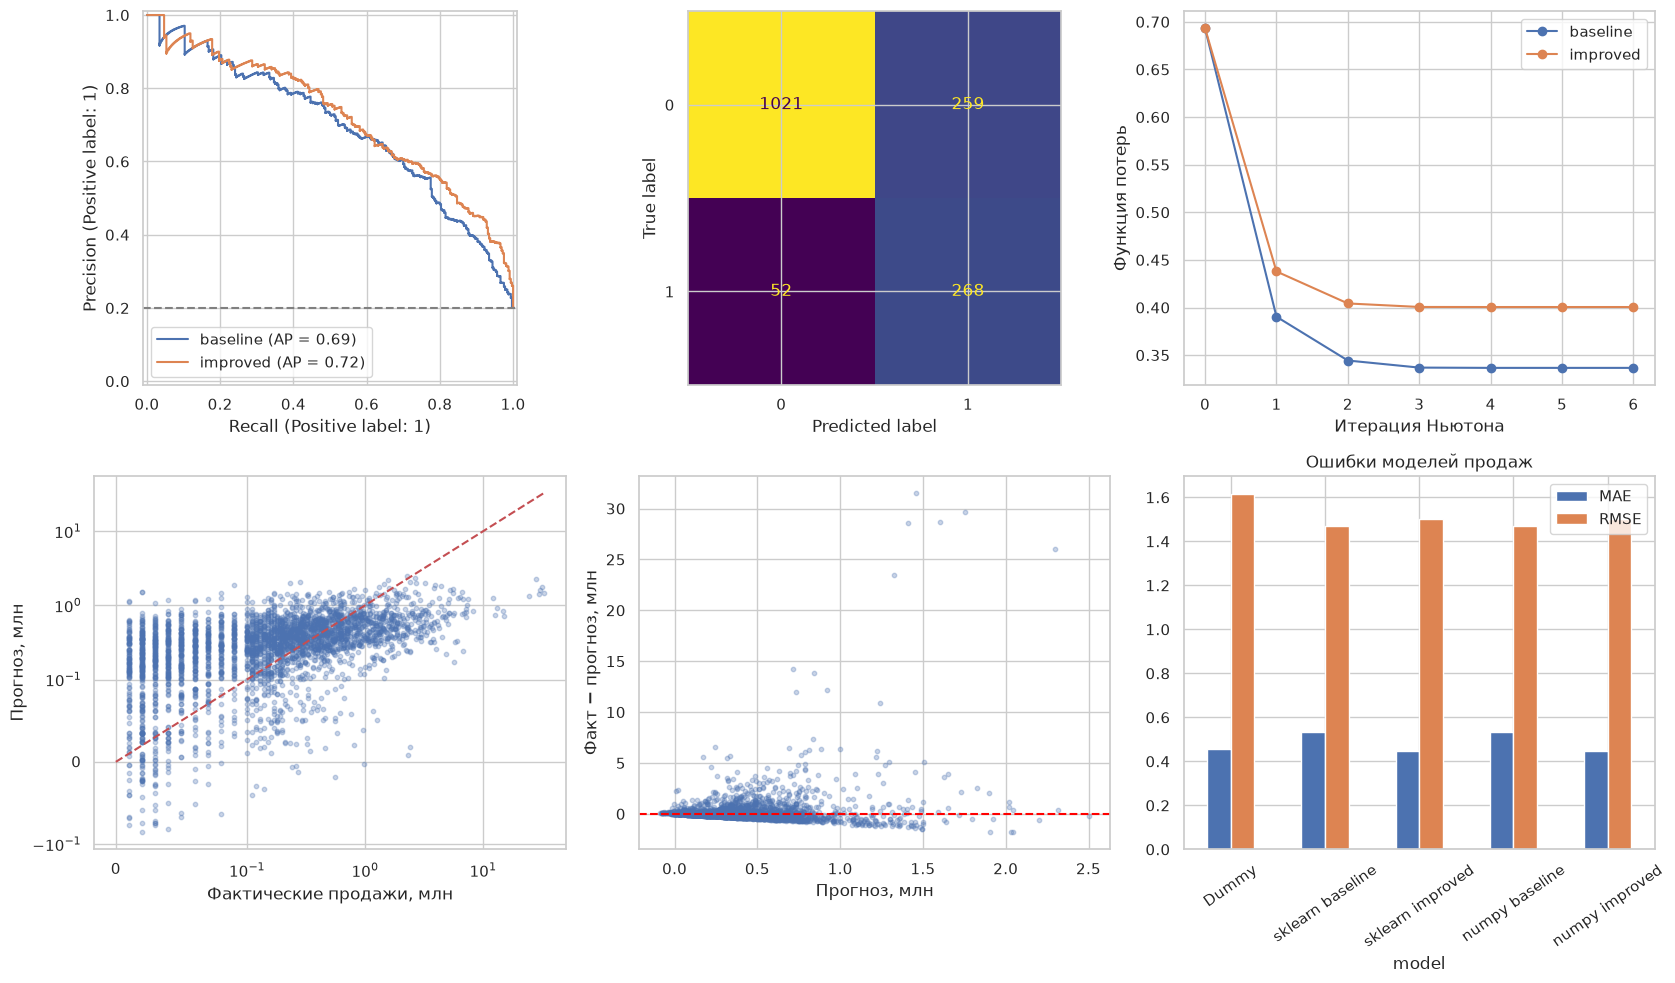

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for stage in ["baseline", "improved"]:
    PrecisionRecallDisplay.from_predictions(yc_test, predictions[("c", "sklearn " + stage)][1], name=stage, ax=axes[0, 0])
axes[0, 0].axhline(yc_test.mean(), color="gray", linestyle="--")
ConfusionMatrixDisplay.from_predictions(yc_test, predictions[("c", "sklearn improved")][0], ax=axes[0, 1], colorbar=False)
for name, model in [("baseline", own_base_c), ("improved", own_improved["c"])]:
    axes[0, 2].plot(model.named_steps["model"].loss_history_, marker="o", label=name)
axes[0, 2].set(xlabel="Итерация Ньютона", ylabel="Функция потерь"); axes[0, 2].legend()
pred = predictions[("r", "sklearn improved")]
axes[1, 0].scatter(yr_test, pred, alpha=.3, s=10)
axes[1, 0].plot([0, yr_test.max()], [0, yr_test.max()], "r--")
axes[1, 0].set_xscale("symlog", linthresh=.1); axes[1, 0].set_yscale("symlog", linthresh=.1)
axes[1, 0].set(xlabel="Фактические продажи, млн", ylabel="Прогноз, млн")
axes[1, 1].scatter(pred, yr_test.to_numpy()-pred, alpha=.3, s=10)
axes[1, 1].axhline(0, color="red", linestyle="--")
axes[1, 1].set(xlabel="Прогноз, млн", ylabel="Факт − прогноз, млн")
metrics[metrics.task == "r"].set_index("model")[["MAE", "RMSE"]].plot.bar(ax=axes[1, 2], rot=35)
axes[1, 2].set_title("Ошибки моделей продаж")
plt.tight_layout(); plt.show()

### Выводы по пунктам 3g, 4e и 4j
Численные выводы строятся по вычисленным результатам. Успех улучшения относительно исходной модели и преимущество перед Dummy проверяем отдельно; вывод не объявляет модель полезной только из-за уменьшения ошибки относительно слабого бейзлайна.

In [13]:
for task, metric, label in [("c", "AP", "Классификация"), ("r", "MAE", "Регрессия")]:
    tab = metrics[metrics.task == task].set_index("model")
    a, b = tab.loc["sklearn baseline", metric], tab.loc["sklearn improved", metric]
    u, v = tab.loc["numpy baseline", metric], tab.loc["numpy improved", metric]
    gain = b-a if task == "c" else a-b
    own_gain = v-u if task == "c" else u-v
    dummy = tab.loc["Dummy", metric]
    beats_dummy = b > dummy if task == "c" else b < dummy
    display(Markdown(f"**{label}.** Выбрано по CV: `{selected[task]}`. "
        f"sklearn {metric}: {a:.5f} → {b:.5f} (выигрыш {gain:+.5f}); "
        f"NumPy: {u:.5f} → {v:.5f} (выигрыш {own_gain:+.5f}). "
        f"NumPy improved минус sklearn improved: {v-b:+.8f}. "
        f"Dummy: {dummy:.5f}. "
        + ("Улучшенная sklearn-модель превзошла Dummy." if beats_dummy else "Улучшенная sklearn-модель не превзошла Dummy по основной метрике.")))

**Классификация.** Выбрано по CV: `H2 tuned logistic`. sklearn AP: 0.69286 → 0.72084 (выигрыш +0.02798); NumPy: 0.69286 → 0.72084 (выигрыш +0.02798). NumPy improved минус sklearn improved: +0.00000000. Dummy: 0.20000. Улучшенная sklearn-модель превзошла Dummy.

**Регрессия.** Выбрано по CV: `H3 tuned log ridge`. sklearn MAE: 0.53478 → 0.44680 (выигрыш +0.08798); NumPy: 0.53478 → 0.44680 (выигрыш +0.08798). NumPy improved минус sklearn improved: +0.00000000. Dummy: 0.45618. Улучшенная sklearn-модель превзошла Dummy.